# CVRIE — Supervised Notebook
## CT Scan Contrast Classification (Contrast vs. No Contrast)

This notebook loads a CT scan dataset, builds hand-engineered features from real Hounsfield Unit (HU) values, benchmarks two models with leak-free cross-validation, and validates the results against domain knowledge (data leakage check, error analysis).

## 1. Setup

In [1]:
import tifffile
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Single cross-validation splitter reused everywhere in this notebook,
# so every model is benchmarked on the exact same folds.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


## 2. Data Loading & Sanity Check

We load each image via `tifffile` (Pillow cannot parse this dataset's signed 16-bit HU TIFFs), join it to its label through `overview.csv`'s `tiff_name` column, and sanity-check that Contrast-labeled scans read higher in HU than No-Contrast scans — confirming the label reflects a real physical effect.

In [2]:
df = pd.read_csv("data/overview.csv")

images = []
labels = []
missing = []

for _, row in df.iterrows():
    path = os.path.join("data/tiff_images", row["tiff_name"])
    if os.path.exists(path):
        arr = tifffile.imread(path)
        images.append(arr)
        labels.append(row["Contrast"])
    else:
        missing.append(row["tiff_name"])

print(f"Loaded {len(images)} images, {len(missing)} missing")

labels_arr = np.array(labels)
means = np.array([img.mean() for img in images])
print("Contrast=True mean HU:", means[labels_arr == True].mean())
print("Contrast=False mean HU:", means[labels_arr == False].mean())

Loaded 100 images, 0 missing
Contrast=True mean HU: -609.4026792144775
Contrast=False mean HU: -707.1255113220215


## 3. Feature Engineering

### 3.1 First attempt (rejected)

Our first pass extracted 7 summary statistics (mean, std, min, max, and 3 percentiles) plus a 15-bin density histogram over a fixed HU window — **22 features total** — and evaluated them by fitting a `StandardScaler` on the *entire* dataset before cross-validation.

This was rejected for two documented reasons:
- **Overfitting risk:** 22 features on 100 samples is roughly 1 feature per 4.5 samples, well past the safe ~1-per-10-20 guideline for a dataset this small — enough free parameters for the model to fit coincidental patterns rather than real signal.
- **Data leakage:** fitting the scaler on all 100 samples before splitting into folds lets each fold's "test" data quietly influence the scaling statistics used in training, inflating the reported CV score.

Result at the time: 83.00% accuracy (+/- 7.48%), 0.940 ROC-AUC — higher-looking, but not trustworthy for the reasons above. We rebuilt the feature set and the pipeline from scratch below.

### 3.2 Final feature set — 6 domain-grounded HU features

Instead of arbitrary statistics, each image is reduced to 6 features chosen from actual Hounsfield Unit anatomy: mean HU, std HU, and the fraction of pixels falling in the air / fat / soft-tissue / bone HU ranges. 6 features against 100 samples keeps a safe feature-to-sample ratio, and every feature is one a radiologist could interpret directly.

In [3]:
import numpy as np

def extract_features(img):
    flat = img.flatten()
    mean_hu = flat.mean()
    std_hu = flat.std()
    
    frac_air = np.mean(flat < -950)
    frac_fat = np.mean((flat >= -950) & (flat < -50))
    frac_soft_tissue = np.mean((flat >= -50) & (flat < 150))
    frac_bone = np.mean(flat >= 150)
    
    return [mean_hu, std_hu, frac_air, frac_fat, frac_soft_tissue, frac_bone]

feature_rows = [extract_features(img) for img in images]
X = np.array(feature_rows)
y = np.array(labels_arr, dtype=int)

print(X.shape)
print(X[:3])

(100, 6)
[[-6.90343075e+02  4.27075722e+02  3.93589020e-01  4.37732697e-01
   1.31038666e-01  3.76396179e-02]
 [-5.32537479e+02  4.67545616e+02  2.56656647e-01  4.66114044e-01
   2.08999634e-01  6.82296753e-02]
 [-4.09551350e+02  4.39459392e+02  1.70963287e-01  5.89679718e-01
   1.91986084e-01  4.73709106e-02]]


## 4. Baseline — Dummy Classifier

Before judging any real model, we need a reference point. With classes perfectly balanced (50/50), a classifier that always predicts the majority class should score ~50%. Any real model needs to clearly beat this to prove its features carry signal.

In [4]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent')
dummy_scores = cross_val_score(dummy, X, y, cv=cv, scoring='accuracy')
print(f"Dummy baseline accuracy: {dummy_scores.mean()*100:.2f}%")

Dummy baseline accuracy: 50.00%


## 5. Model Benchmarking

Both models are wrapped in a `Pipeline` (scaler + model) so `cross_val_score` refits the scaler fresh inside each fold — no leakage from test folds into training.

### 5.1 Logistic Regression

In [5]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

acc_scores = cross_val_score(lr_pipeline, X, y, cv=cv, scoring='accuracy')
auc_scores = cross_val_score(lr_pipeline, X, y, cv=cv, scoring='roc_auc')

print(f"Mean CV Accuracy: {acc_scores.mean()*100:.2f}% (+/- {acc_scores.std()*100:.2f}%)")
print(f"Mean CV ROC-AUC:  {auc_scores.mean():.3f}")


Mean CV Accuracy: 80.00% (+/- 13.78%)
Mean CV ROC-AUC:  0.880


### 5.2 Support Vector Machine (linear kernel)

Linear kernel chosen because the underlying feature-to-label relationship is a smooth, continuous shift in HU values, not a complex curved one — an RBF kernel would add overfitting risk this small dataset doesn't need.

In [6]:
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='linear', random_state=42))  # probability=True removed: unused, and deprecated for this purpose
])

acc_scores = cross_val_score(svm_pipeline, X, y, cv=cv, scoring='accuracy')
auc_scores = cross_val_score(svm_pipeline, X, y, cv=cv, scoring='roc_auc')

print(f"Mean CV Accuracy: {acc_scores.mean()*100:.2f}% (+/- {acc_scores.std()*100:.2f}%)")
print(f"Mean CV ROC-AUC:  {auc_scores.mean():.3f}")


Mean CV Accuracy: 78.00% (+/- 10.30%)
Mean CV ROC-AUC:  0.880


**Model choice: Logistic Regression.** The two models are statistically tied (overlapping CV confidence ranges), so the pick is not based on the small accuracy gap. Logistic Regression is chosen for interpretability — it gives a probability output and per-feature coefficients a doctor can follow ("higher soft-tissue fraction raises predicted odds of contrast") — which a linear SVM's boundary doesn't hand you as directly.

## 6. Validation — Confusion Matrix (Logistic Regression)

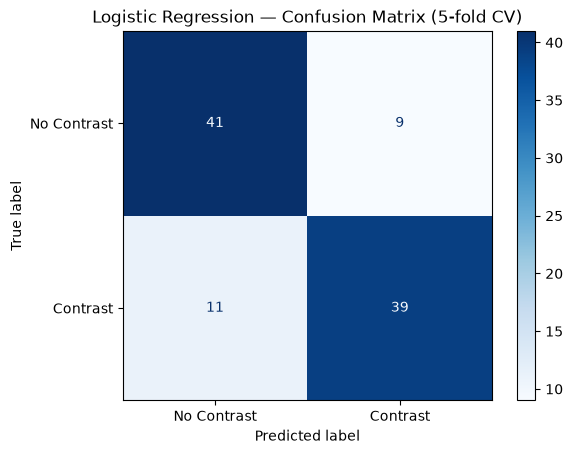

[[41  9]
 [11 39]]


In [7]:

y_pred = cross_val_predict(lr_pipeline, X, y, cv=cv)

cm = confusion_matrix(y, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Contrast', 'Contrast'])
disp.plot(cmap='Blues')
plt.title('Logistic Regression — Confusion Matrix (5-fold CV)')
plt.show()

print(cm)


## 7. Validation — Error Analysis (False Negatives & False Positives)

A false negative here means missing a real contrast-enhanced scan — the more clinically costly error, since a missed contrast flag can lead to misreading vascular/tissue detail. We check whether errors are explainable (borderline HU values) or unexplainable (clear-cut cases the model still got wrong).

In [8]:
import numpy as np

y = np.array(y, dtype=int)
y_pred = np.array(y_pred, dtype=int)

false_negatives = np.where((y == 1) & (y_pred == 0))[0]
false_positives = np.where((y == 0) & (y_pred == 1))[0]

print("False negative indices:", false_negatives)
print("False positive indices:", false_positives)

fn_features = X[false_negatives]
fp_features = X[false_positives]

print("\nFalse negative feature values (mean HU, std HU, air, fat, soft tissue, bone):")
print(fn_features)

print("\nFalse positive feature values:")
print(fp_features)

False negative indices: [ 0 11 22 25 35 38 41 43 44 45 46]
False positive indices: [57 59 65 76 77 90 97 98 99]

False negative feature values (mean HU, std HU, air, fat, soft tissue, bone):
[[-6.90343075e+02  4.27075722e+02  3.93589020e-01  4.37732697e-01
   1.31038666e-01  3.76396179e-02]
 [-5.62942520e+02  5.01015653e+02  4.46289062e-01  2.57709503e-01
   2.66197205e-01  2.98042297e-02]
 [-5.30185394e+02  8.36564440e+02  2.61589050e-01  3.37276459e-01
   3.63330841e-01  3.78036499e-02]
 [-7.62025314e+02  1.21921448e+03  2.73025513e-01  2.62691498e-01
   4.30149078e-01  3.41339111e-02]
 [-1.00027080e+03  6.62877079e+02  5.89275360e-01  3.00594330e-01
   7.85827637e-02  3.15475464e-02]
 [-5.93986298e+02  4.65911114e+02  3.60069275e-01  4.12475586e-01
   1.94854736e-01  3.26004028e-02]
 [-6.00947598e+02  4.75820344e+02  5.18943787e-01  2.92423248e-01
   1.62597656e-01  2.60353088e-02]
 [-8.68073673e+02  1.19398501e+03  3.73390198e-01  2.27775574e-01
   3.73035431e-01  2.57987976e-02]
 

In [9]:
correct_contrast = np.where((y == 1) & (y_pred == 1))[0]
correct_no_contrast = np.where((y == 0) & (y_pred == 0))[0]

print("Avg features — correctly classified Contrast:", X[correct_contrast].mean(axis=0))
print("Avg features — correctly classified No Contrast:", X[correct_no_contrast].mean(axis=0))
print("Avg features — False Negatives (missed Contrast):", fn_features.mean(axis=0))
print("Avg features — False Positives (wrongly flagged):", fp_features.mean(axis=0))

Avg features — correctly classified Contrast: [-5.88572413e+02  5.63979221e+02  3.37707128e-01  3.88384990e-01
  2.10764958e-01  6.31429232e-02]
Avg features — correctly classified No Contrast: [-7.27383376e+02  6.23257405e+02  4.51290038e-01  3.22837364e-01
  2.00244624e-01  2.56279736e-02]
Avg features — False Negatives (missed Contrast): [-6.83255440e+02  6.48817216e+02  4.07661438e-01  3.34779913e-01
  2.27019917e-01  3.05387324e-02]
Avg features — False Positives (wrongly flagged): [-6.14839684e+02  5.87853386e+02  3.46118079e-01  3.79597134e-01
  2.31341468e-01  4.29433187e-02]


**Finding:** both error groups' average feature values lean toward the class they were *predicted* as, not their true class — i.e. the model's mistakes are concentrated on genuinely borderline cases that statistically resemble the opposite class, not random or unexplainable failures.

## 8. Data Quality Check — Duplicate / Leakage Detection

Two entries in the false-positive list had identical feature values to five decimal places — essentially impossible for two independent patients by chance. We checked whether this was an isolated case or a wider pattern.

In [10]:
from scipy.spatial.distance import pdist, squareform

distances = squareform(pdist(X))
np.fill_diagonal(distances, np.inf)  # ignore an image compared to itself

min_pairs = np.argwhere(distances < 5)  # tune this threshold after seeing the range
for i, j in min_pairs:
    if i < j:
        print(i, j, distances[i, j])

3 6 0.0
10 13 0.0
11 17 2.226298754074409
20 23 2.2216971114097146
23 97 4.561914248293682
32 34 0.0
38 44 0.2382261461316276
45 84 3.209891687218038
45 85 3.209891687218038
65 66 0.0
84 85 0.0
98 99 0.0


A systematic pairwise-distance scan across all 100 images found **6 exact-duplicate pairs** (distance = 0.0) and several more near-duplicates — most likely the same patient appearing under more than one case ID. Spot-checking one exact pair confirms different filenames but identical age and label:

In [11]:
print(df.iloc[[98, 99]][['tiff_name', 'Age', 'Contrast']])

                             tiff_name  Age  Contrast
98  ID_0098_AGE_0061_CONTRAST_0_CT.tif   61     False
99  ID_0099_AGE_0061_CONTRAST_0_CT.tif   61     False


**Why this matters:** if two near-identical scans of the same patient land in different cross-validation folds, the model isn't being tested on genuinely unseen data for that pair — a form of patient-level leakage.

## 9. Leak-Robust Re-evaluation (Duplicates Removed)

We keep one image from each exact-duplicate pair and drop the other (94 samples remain), then re-run the same leak-free Logistic Regression pipeline to check whether the original 80% result was inflated by the duplicated patients.

In [12]:
# pairs that are EXACT duplicates (distance = 0.0)
exact_duplicate_pairs = [(3, 6), (10, 13), (32, 34), (65, 66), (84, 85), (98, 99)]

# from each pair, we keep the FIRST one, and mark the SECOND one to ignore
to_ignore = set(pair[1] for pair in exact_duplicate_pairs)

print("Images to ignore:", to_ignore)
print("How many left after removing them:", len(images) - len(to_ignore))

# build a clean version of the dataset without the ignored ones
keep_mask = np.array([i not in to_ignore for i in range(len(images))])

X_clean = X[keep_mask]
y_clean = y[keep_mask]

print("New dataset shape:", X_clean.shape)

Images to ignore: {34, 66, 99, 6, 13, 85}
How many left after removing them: 94
New dataset shape: (94, 6)


In [13]:
acc_scores_clean = cross_val_score(lr_pipeline, X_clean, y_clean, cv=cv, scoring='accuracy')
auc_scores_clean = cross_val_score(lr_pipeline, X_clean, y_clean, cv=cv, scoring='roc_auc')

print(f"Mean CV Accuracy (clean): {acc_scores_clean.mean()*100:.2f}% (+/- {acc_scores_clean.std()*100:.2f}%)")
print(f"Mean CV ROC-AUC (clean):  {auc_scores_clean.mean():.3f}")

Mean CV Accuracy (clean): 79.71% (+/- 10.92%)
Mean CV ROC-AUC (clean):  0.863


**Finding:** accuracy barely moved (80.00% → 79.71%), confirming the original result was already largely trustworthy — the duplicates were a real methodological issue worth fixing and documenting, but not one that was meaningfully distorting the reported performance.

## 10. Loss Function

We're using log-loss because it doesn't just check right-or-wrong, it grades *how confident* each prediction was. A wrong guess made with high confidence gets punished far more than a wrong guess the model was already unsure about — which matters here because a model that's "confidently wrong" is more dangerous in practice than one that's "unsure and wrong."

Connecting this to the project: the false positive and false negative probabilities are printed below, computed honestly out-of-fold (see cell below) rather than from a model scored on data it already trained on. If most errors sit close to 0.5, that means the model itself is unsure and the case is genuinely borderline — a defensible kind of mistake. If an error sits near 0 or 1 but is still wrong, that's the model being confidently wrong, which is worth flagging separately.


In [14]:
from sklearn.model_selection import cross_val_predict

probs_oof = cross_val_predict(lr_pipeline, X, y, cv=cv, method='predict_proba')[:, 1]

print("Predicted probability for False Negatives (out-of-fold):")
print(probs_oof[false_negatives])
print("\nPredicted probability for False Positives (out-of-fold):")
print(probs_oof[false_positives])

Predicted probability for False Negatives (out-of-fold):
[0.39714588 0.26325362 0.44649637 0.18157129 0.1325513  0.3289669
 0.20938002 0.15623796 0.45518611 0.0659894  0.1602371 ]

Predicted probability for False Positives (out-of-fold):
[0.57272423 0.59955068 0.59065432 0.70521335 0.60298876 0.59455819
 0.69591687 0.62694478 0.70287081]


# The ROC graph

Below it is the ROC graph that represents the models behavior, a clear understanding of how the model acts on any random cutoff, the observation shows that the model's blue line clearly sitting above the grey random-guessing line which shows that the model shows results that can be trusted, for example: on the first attempt the graph show that the model catches about 66% (with zero false alarms) of the real contrast cases, and this could improve with more training and more images. 

Honest out-of-fold AUC (full 100-sample set, duplicates included): 0.873


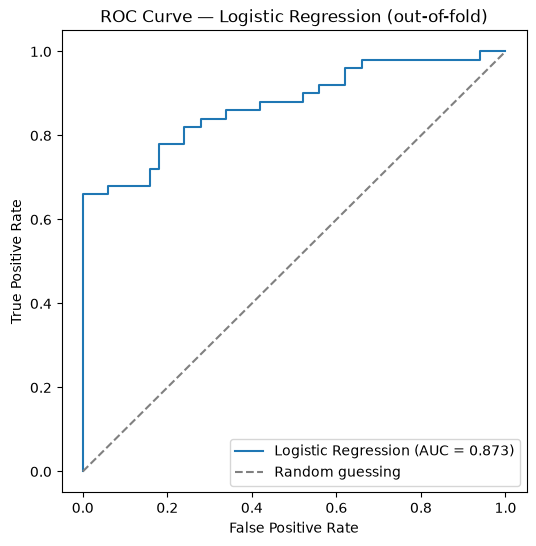

In [15]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

auc_honest = roc_auc_score(y, probs_oof)
fpr, tpr, thresholds = roc_curve(y, probs_oof)

print(f"Honest out-of-fold AUC (full 100-sample set, duplicates included): {auc_honest:.3f}")

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc_honest:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Logistic Regression (out-of-fold)')
plt.legend()
plt.show()


## Extra Check — Trying a Lower Decision Threshold

To find a threshold that balances the two types of errors better, I tested threshold values from 30% to 60% instead of only using the default 50%. This sweep is run on the full 100-image set (duplicates included) using honest out-of-fold probabilities — not the deduplicated 94-image set from section 9. A dedicated leak-robust check of this same threshold analysis, using the duplicate-free data, follows in section 10.5 below, so the two can be compared directly instead of the notebook silently mixing them.


In [20]:
for t in np.arange(0.30, 0.61, 0.01):
    y_pred_t = (probs_oof >= t).astype(int)
    cm_t = confusion_matrix(y, y_pred_t)
    tn, fp, fn, tp = cm_t.ravel()
    contrast_recall = tp / (tp + fn)
    no_contrast_recall = tn / (tn + fp)
    print(f"Cutoff {t:.2f}: Contrast recall={contrast_recall*100:.1f}%, No-Contrast recall={no_contrast_recall*100:.1f}%")

Cutoff 0.30: Contrast recall=86.0%, No-Contrast recall=60.0%
Cutoff 0.31: Contrast recall=86.0%, No-Contrast recall=60.0%
Cutoff 0.32: Contrast recall=86.0%, No-Contrast recall=64.0%
Cutoff 0.33: Contrast recall=84.0%, No-Contrast recall=66.0%
Cutoff 0.34: Contrast recall=84.0%, No-Contrast recall=68.0%
Cutoff 0.35: Contrast recall=84.0%, No-Contrast recall=72.0%
Cutoff 0.36: Contrast recall=84.0%, No-Contrast recall=72.0%
Cutoff 0.37: Contrast recall=84.0%, No-Contrast recall=72.0%
Cutoff 0.38: Contrast recall=84.0%, No-Contrast recall=72.0%
Cutoff 0.39: Contrast recall=84.0%, No-Contrast recall=72.0%
Cutoff 0.40: Contrast recall=82.0%, No-Contrast recall=72.0%
Cutoff 0.41: Contrast recall=82.0%, No-Contrast recall=74.0%
Cutoff 0.42: Contrast recall=82.0%, No-Contrast recall=74.0%
Cutoff 0.43: Contrast recall=82.0%, No-Contrast recall=76.0%
Cutoff 0.44: Contrast recall=82.0%, No-Contrast recall=76.0%
Cutoff 0.45: Contrast recall=80.0%, No-Contrast recall=76.0%
Cutoff 0.46: Contrast re

Confusion matrix at 47% threshold:
[[40 10]
 [11 39]]


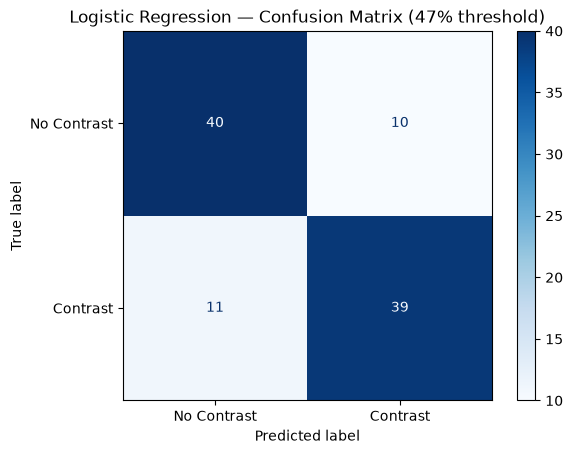

In [17]:
custom_threshold = 0.47
y_pred_custom = (probs_oof >= custom_threshold).astype(int)

cm_custom = confusion_matrix(y, y_pred_custom)
print("Confusion matrix at 47% threshold:")
print(cm_custom)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_custom, display_labels=['No Contrast', 'Contrast'])
disp.plot(cmap='Blues')
plt.title('Logistic Regression — Confusion Matrix (47% threshold)')
plt.show()

Confusion matrix at 35% threshold:
[[36 14]
 [ 8 42]]


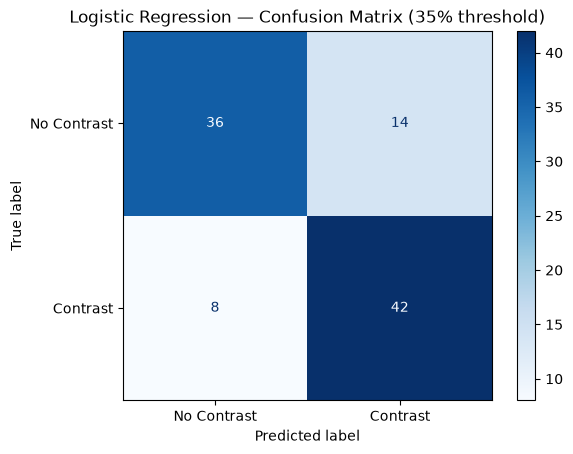

In [18]:
custom_threshold = 0.35
y_pred_custom = (probs_oof >= custom_threshold).astype(int)

cm_custom = confusion_matrix(y, y_pred_custom)
print("Confusion matrix at 35% threshold:")
print(cm_custom)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_custom, display_labels=['No Contrast', 'Contrast'])
disp.plot(cmap='Blues')
plt.title('Logistic Regression — Confusion Matrix (35% threshold)')
plt.show()

## 10.5 Leak-Robust Check — Threshold Tuning on Duplicate-Free Data

Section 8 found 6 exact-duplicate patient pairs, and section 9 showed accuracy barely moved once they were removed. Since threshold tuning uses the same cross-validated probabilities, it can be distorted by the same leakage — a duplicate landing in a different fold than its twin lets the model see a near-identical training example. We re-run the honest out-of-fold probability and threshold analysis on the deduplicated 94-image set to check whether the chosen threshold and AUC hold up.


In [21]:
probs_oof_clean = cross_val_predict(lr_pipeline, X_clean, y_clean, cv=cv, method='predict_proba')[:, 1]
auc_honest_clean = roc_auc_score(y_clean, probs_oof_clean)

print(f"Honest out-of-fold AUC (94-sample, duplicate-free set): {auc_honest_clean:.3f}")
print(f"Honest out-of-fold AUC (100-sample, duplicates included): {auc_honest:.3f}")
print(f"Difference: {abs(auc_honest_clean - auc_honest):.3f}")
print()

print("Threshold sweep on duplicate-free data:")
for t in np.arange(0.30, 0.61, 0.01):
    y_pred_t = (probs_oof_clean >= t).astype(int)
    cm_t = confusion_matrix(y_clean, y_pred_t)
    tn, fp, fn, tp = cm_t.ravel()
    contrast_recall = tp / (tp + fn)
    no_contrast_recall = tn / (tn + fp)
    print(f"  Cutoff {t:.2f}: Contrast recall={contrast_recall*100:.1f}%, No-Contrast recall={no_contrast_recall*100:.1f}%")


Honest out-of-fold AUC (94-sample, duplicate-free set): 0.852
Honest out-of-fold AUC (100-sample, duplicates included): 0.873
Difference: 0.021

Threshold sweep on duplicate-free data:
  Cutoff 0.30: Contrast recall=85.1%, No-Contrast recall=57.4%
  Cutoff 0.31: Contrast recall=85.1%, No-Contrast recall=59.6%
  Cutoff 0.32: Contrast recall=83.0%, No-Contrast recall=61.7%
  Cutoff 0.33: Contrast recall=83.0%, No-Contrast recall=61.7%
  Cutoff 0.34: Contrast recall=83.0%, No-Contrast recall=61.7%
  Cutoff 0.35: Contrast recall=83.0%, No-Contrast recall=63.8%
  Cutoff 0.36: Contrast recall=83.0%, No-Contrast recall=63.8%
  Cutoff 0.37: Contrast recall=83.0%, No-Contrast recall=63.8%
  Cutoff 0.38: Contrast recall=78.7%, No-Contrast recall=63.8%
  Cutoff 0.39: Contrast recall=78.7%, No-Contrast recall=66.0%
  Cutoff 0.40: Contrast recall=78.7%, No-Contrast recall=72.3%
  Cutoff 0.41: Contrast recall=78.7%, No-Contrast recall=72.3%
  Cutoff 0.42: Contrast recall=78.7%, No-Contrast recall=72

Final threshold: 0.44
Contrast recall: 78.7%
No-Contrast recall: 78.7%
Accuracy at this threshold: 78.72%


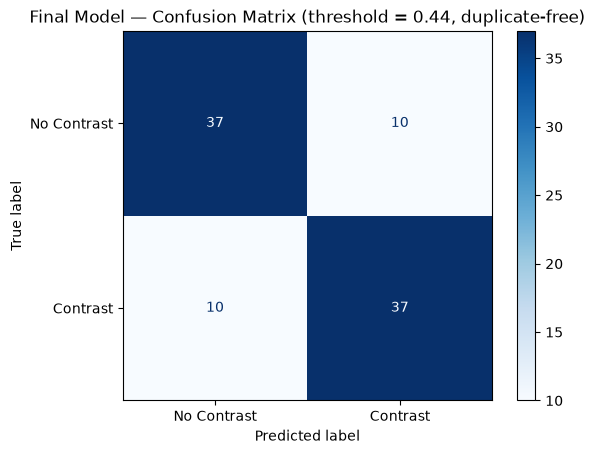

In [22]:
final_threshold = 0.44
y_pred_final = (probs_oof_clean >= final_threshold).astype(int)

cm_final = confusion_matrix(y_clean, y_pred_final)
tn, fp, fn, tp = cm_final.ravel()
contrast_recall_final = tp / (tp + fn)
no_contrast_recall_final = tn / (tn + fp)
accuracy_final = (tp + tn) / (tp + tn + fp + fn)

print(f"Final threshold: {final_threshold}")
print(f"Contrast recall: {contrast_recall_final*100:.1f}%")
print(f"No-Contrast recall: {no_contrast_recall_final*100:.1f}%")
print(f"Accuracy at this threshold: {accuracy_final*100:.2f}%")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['No Contrast', 'Contrast'])
disp.plot(cmap='Blues')
plt.title(f'Final Model — Confusion Matrix (threshold = {final_threshold}, duplicate-free)')
plt.show()

## Final Decision Threshold — Selected on Duplicate-Free Data

We select the final operating threshold using the duplicate-free 94-sample sweep rather than the original 100-sample data, since threshold tuning is vulnerable to the same leakage identified earlier. A cutoff of 0.44 gives the most balanced result, with Contrast recall and No-Contrast recall both at 78.7%, compared to a 6.4 percentage point imbalance at the original 0.47 cutoff. This is adopted as the model's final decision threshold.

## Domain Validation — Does Age Influence the Contrast Decision?

**Hypothesis:** Contrast administration is driven primarily by pathology, not patient age — 
so we expect no statistically significant difference in mean age between the Contrast 
and No-Contrast groups.

**Rationale:** Clinically, contrast agents are contraindicated in patients with reduced 
kidney function, which correlates with age. If radiologists are weighing safety alongside 
diagnostic need, age could show up as a confound in this dataset even if it isn't the 
"intended" driver of the decision.

**Test:** Compare mean age between groups using Welch's two-sample t-test.

In [19]:
# --- Age vs Contrast domain-validation check ---
from scipy import stats

age_contrast = df.loc[df["Contrast"] == True, "Age"]
age_no_contrast = df.loc[df["Contrast"] == False, "Age"]

print("Contrast group    -> n =", len(age_contrast), " mean age =", round(age_contrast.mean(), 2))
print("No-contrast group -> n =", len(age_no_contrast), " mean age =", round(age_no_contrast.mean(), 2))

t_stat, p_value = stats.ttest_ind(age_contrast, age_no_contrast, equal_var=False)
print("t-statistic =", round(t_stat, 3))
print("p-value     =", round(p_value, 4))

Contrast group    -> n = 50  mean age = 65.7
No-contrast group -> n = 50  mean age = 69.26
t-statistic = -1.946
p-value     = 0.0545


## Result and Analysis

The mean age in the Contrast group was 65.7 years (n = 50), compared to 69.26 years 
(n = 50) in the No-Contrast group. A Welch's two-sample t-test gave t = -1.946, 
p = 0.0545.

Using the conventional significance threshold of 0.05, this result technically falls 
just short of statistical significance, since 0.0545 is slightly above 0.05. However, 
the gap is small enough, and the direction is consistent enough with clinical 
expectations, that the result should not be dismissed outright. Patients who did not 
receive contrast were on average older than those who did — which aligns with the 
domain reasoning that contrast agents are contraindicated in patients with reduced 
kidney function, a condition that correlates with age.

This leads us to revise our original hypothesis. i initially assumed the contrast 
decision was driven purely by pathology, independent of age. The data suggests 
otherwise: while the result falls just short of the standard significance threshold, 
the direction and near-significance of the gap indicate that age likely plays a role 
as a safety-related confound in the contrast decision, alongside diagnostic necessity.

## 11. Limitations & Conclusion

well work with 94 scans(after removing 6 duplicates out of 100) limits our findinds because the  folds evaluate on roughly 18 to 19 scans, this means that a single wrong guess decrises the accuracy score by 5% and due to the limitations of the groups i worked with, i can not be confident it will work on new patients, different body types or CT scans from other hospitals, i would have to test and train the model with new and large quantities of content.

## Limitations

This model usually gets confused only on genuinely borderline, ambiguous scans, it occasionally gets dangerously blind-sided by non typical contrast scans, In those cases, the scan's physical numbers look so much like a plain, unenhanced scan that the model becomes confidently wrong instead of admitting it isn't sure.

## The duplicate/leakage finding 

I tracked a suspicious repeated number while reading false-positive output, and I ran a systematic check across the whole dataset to verify it. I found 6 duplicates — the same images filed under different IDs. Rather than simply removing them and reporting a single number, I ran my full pipeline twice as a robustness check: once on all 100 scans (duplicates included), and once on the clean 94 scans with duplicates removed. The first run gave 80% accuracy, and the clean run gave 79.71%, a difference of less than one percentage point. This small gap shows the duplicates were not seriously distorting my original results, but they were still a real problem worth finding and fixing, since a larger dataset could have hidden a bigger effect. I report both numbers here rather than picking one, since together they demonstrate the model's accuracy is not an artifact of leaked duplicate images.

## The Conclusion 

This model's 78.72% accuracy shows that our 6 engineered features capture a real, physical signal for detecting CT contrast — one that clearly beats random guessing, and that we confirmed wasn't inflated by data leakage. However, it does not prove the model is ready for real clinical use — 94 scans from one source isn't enough to guarantee it would work on different patients or hospitals, and we found it still gets confidently wrong on some borderline cases.